# 07 Gradient boosting, direct price target, 09:00 cutoff

First model: histogram gradient boosting (scikit-learn) predicting the price directly, on the 17 chronological folds (D-007), scored with the tail metrics (D-004) and compared paired by fold against the 28-day same-period median. 09:00 rows only (demand is available there). Hyper-parameters are fixed in advance, not tuned on these folds.

## Init

In [1]:
import sys
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from _eval import make_folds, score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds_exp = make_folds(days, 28, 17, 1)
folds_sli = make_folds(days, 28, 17, 1, train_window=180)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds_exp]))
VAL = D9["day"].isin(val_days_all)
print(len(D9), "rows at 09:00;", int(VAL.sum()), "validation rows in", len(folds_exp), "folds")

32351 rows at 09:00; 22847 validation rows in 17 folds


## 1. Setup

**Feature sets** (so we can see what each group adds beyond the 28-day profile):
- **A**: calendar plus price history (profile medians, D-2, levels).
- **B**: A plus the weather/demand forecasts.
- **C**: B plus the daily margin features.

**Model**: `HistGradientBoostingRegressor`, 300 iterations, learning rate 0.05, at most 15 leaves, at least 100 rows per leaf, L2 = 1, no early stopping (so validation data never steers training). It handles missing values natively, so the 07:00-style gaps need no imputation. Primary loss is absolute error (robust to the price tail); squared error is run once for contrast. Two training windows: expanding and the last 180 days.

In [2]:
CAL = ["hour_frac", "weekday", "is_weekend", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
HIST = ["d2_same", "med7_same", "med28_same", "level7", "level28", "level24h", "level_gap"]
FC = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw", "wind_total_mw",
      "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"]
MG = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
SETS = {"A": CAL + HIST, "B": CAL + HIST + FC, "C": CAL + HIST + FC + MG}

HP = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100,
          l2_regularization=1.0, early_stopping=False, random_state=0)

def run_cv(cols, loss, folds):
    pred = pd.Series(np.nan, index=D9.index)
    for f in folds:
        tr = D9[D9["day"].isin(f["train_days"]) & D9["price"].notna()]
        va = D9[D9["day"].isin(f["val_days"])]
        m = HistGradientBoostingRegressor(loss=loss, **HP).fit(tr[cols], tr["price"])
        pred.loc[va.index] = m.predict(va[cols])
    return pred

def fold_table(pred_col):
    rows = []
    for f in folds_exp:
        d = D9[D9["day"].isin(f["val_days"])].assign(pred=pred_col)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

base_pred = D9["med28_same"]
BASE = fold_table(base_pred)
print(BASE[["MAE", "RMSE", "hit_top8", "hit_bot8", "MAE_top10", "MAE_bot10"]].mean().round(3).to_string())

MAE          30.200
RMSE         41.074
hit_top8      0.462
hit_bot8      0.322
MAE_top10    47.435
MAE_bot10    73.820


## 2. Run the configurations

Eight configurations: feature sets A, B, C with absolute-error loss on both windows, plus C with squared error on both windows. Nothing is selected on the basis of these numbers; all are reported.

In [3]:
import time
CFG = {}
for name, cols, loss, win in [
    ("A abs expanding", SETS["A"], "absolute_error", "exp"), ("A abs sliding", SETS["A"], "absolute_error", "sli"),
    ("B abs expanding", SETS["B"], "absolute_error", "exp"), ("B abs sliding", SETS["B"], "absolute_error", "sli"),
    ("C abs expanding", SETS["C"], "absolute_error", "exp"), ("C abs sliding", SETS["C"], "absolute_error", "sli"),
    ("C sq expanding", SETS["C"], "squared_error", "exp"), ("C sq sliding", SETS["C"], "squared_error", "sli")]:
    t0 = time.time()
    CFG[name] = run_cv(cols, loss, folds_exp if win == "exp" else folds_sli)
    print(f"{name:18s} {time.time() - t0:5.1f}s")
P = pd.DataFrame(CFG)
P["day"] = D9["day"]; P["period_start"] = D9["period_start"]; P["price"] = D9["price"]; P["med28_same"] = D9["med28_same"]
P.loc[VAL].to_parquet("outputs/cv_preds_gbm_direct_0900.parquet", index=False)

A abs expanding     12.9s


A abs sliding        9.7s


B abs expanding     13.4s


B abs sliding       10.5s


C abs expanding     14.1s


C abs sliding       11.0s


C sq expanding       9.5s


C sq sliding         7.2s


## 3. Pooled scores

All rows of the 17 validation blocks together. The baseline is the 28-day same-period median.

In [4]:
rows = {"28-day median (baseline)": score(D9[VAL].assign(pred=base_pred[VAL]), "pred")}
for name in CFG:
    rows[name] = score(D9[VAL].assign(pred=P.loc[VAL, name]), "pred")
R = pd.DataFrame(rows).T
print(R[["MAE", "RMSE", "bias", "hit_top8", "hit_bot8", "MAE_top10", "MAE_bot10"]].round(3).to_string())

                             MAE    RMSE    bias  hit_top8  hit_bot8  MAE_top10  MAE_bot10
28-day median (baseline)  30.200  42.230   1.890     0.462     0.322     49.103     82.293
A abs expanding           32.631  44.046  -2.570     0.461     0.326     57.511     72.251
A abs sliding             36.117  47.918 -10.205     0.459     0.304     63.311     70.736
B abs expanding           28.775  38.678  -3.698     0.491     0.359     54.398     47.506
B abs sliding             29.100  39.063  -4.306     0.475     0.346     54.214     49.935
C abs expanding           28.571  38.521  -3.588     0.488     0.364     53.836     46.902
C abs sliding             28.686  38.738  -4.174     0.477     0.346     52.592     49.515
C sq expanding            29.258  41.432  -3.079     0.483     0.368     55.625     45.636
C sq sliding              28.906  38.674  -4.586     0.467     0.345     53.053     48.684


## 4. Paired by fold

For each configuration and metric, the per-fold difference to the baseline (model minus baseline for errors; model minus baseline for hit rates, where higher is better). The count is the number of folds out of 17 in which the model is better. A real improvement should be consistent, not driven by one or two folds.

In [5]:
def paired(name):
    ft = fold_table(P[name])
    out = {}
    for m, better_low in [("MAE", True), ("RMSE", True), ("hit_top8", False), ("hit_bot8", False), ("MAE_top10", True), ("MAE_bot10", True)]:
        diff = ft[m] - BASE[m]
        wins = (diff < 0).sum() if better_low else (diff > 0).sum()
        out[m] = f"{diff.mean():+.2f} ({wins}/17)" if m.startswith(("MAE", "RMSE")) else f"{diff.mean():+.3f} ({wins}/17)"
    return out
PT = pd.DataFrame({n: paired(n) for n in CFG}).T
print("mean per-fold difference to the baseline (folds where the model is better)")
print(PT.to_string())

mean per-fold difference to the baseline (folds where the model is better)
                           MAE           RMSE        hit_top8        hit_bot8      MAE_top10       MAE_bot10
A abs expanding   +2.43 (4/17)   +1.76 (6/17)  -0.001 (10/17)  +0.004 (10/17)   +1.68 (9/17)   -9.30 (11/17)
A abs sliding     +5.92 (1/17)   +5.43 (3/17)   -0.003 (7/17)   -0.018 (4/17)   +9.92 (5/17)  -13.66 (15/17)
B abs expanding  -1.43 (11/17)  -3.24 (14/17)  +0.028 (14/17)  +0.037 (12/17)  -2.92 (10/17)  -30.18 (16/17)
B abs sliding     -1.10 (9/17)  -2.87 (14/17)  +0.013 (11/17)  +0.024 (11/17)   -1.06 (9/17)  -28.68 (17/17)
C abs expanding  -1.63 (11/17)  -3.39 (13/17)  +0.026 (15/17)  +0.042 (13/17)  -3.73 (10/17)  -31.07 (17/17)
C abs sliding    -1.51 (13/17)  -3.31 (15/17)  +0.014 (11/17)   +0.024 (9/17)  -2.20 (10/17)  -28.50 (17/17)
C sq expanding   -0.94 (10/17)  -1.65 (12/17)  +0.021 (13/17)  +0.046 (13/17)   -0.30 (8/17)  -32.00 (16/17)
C sq sliding      -1.29 (9/17)  -3.33 (13/17)  +0.005

### Size of the paired differences against their fold-to-fold noise

Mean per-fold difference to the baseline with its standard error (std of the 17 differences / sqrt(17)). A mean more than about two standard errors from zero is unlikely to be fold noise, though 17 folds of adjacent time blocks are not fully independent.

In [6]:
rows = {}
for n in ["A abs expanding", "B abs expanding", "C abs expanding", "C abs sliding", "C sq sliding"]:
    ft = fold_table(P[n]); r = {}
    for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]:
        d = ft[m] - BASE[m]
        r[m] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(len(d)):.3f}"
    rows[n] = r
print(pd.DataFrame(rows).T.to_string())

                              MAE              RMSE          hit_top8          hit_bot8
A abs expanding  +2.431 +/- 0.731  +1.761 +/- 0.874  -0.001 +/- 0.005  +0.004 +/- 0.008
B abs expanding  -1.425 +/- 0.796  -3.240 +/- 0.996  +0.028 +/- 0.006  +0.037 +/- 0.013
C abs expanding  -1.629 +/- 0.779  -3.388 +/- 0.970  +0.026 +/- 0.004  +0.042 +/- 0.012
C abs sliding    -1.514 +/- 0.823  -3.311 +/- 0.966  +0.014 +/- 0.007  +0.024 +/- 0.015
C sq sliding     -1.294 +/- 0.738  -3.327 +/- 0.950  +0.005 +/- 0.011  +0.023 +/- 0.014


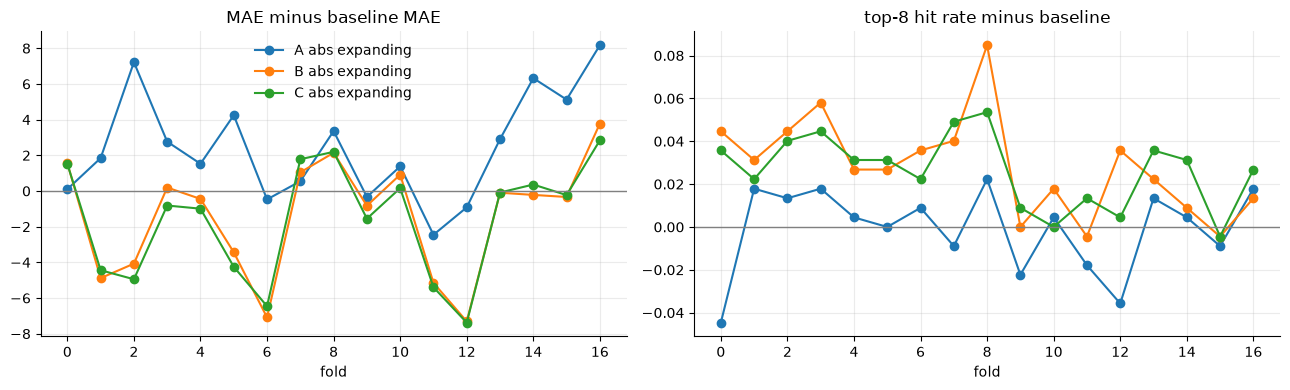

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in ["A abs expanding", "B abs expanding", "C abs expanding"]:
    axes[0].plot(fold_table(P[name])["MAE"] - BASE["MAE"], marker="o", label=name)
    axes[1].plot(fold_table(P[name])["hit_top8"] - BASE["hit_top8"], marker="o", label=name)
for ax, t in zip(axes, ["MAE minus baseline MAE", "top-8 hit rate minus baseline"]):
    ax.axhline(0, color="grey", lw=1); ax.set_title(t); ax.set_xlabel("fold")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Which features matter

Permutation importance (increase in MAE when one feature is shuffled in the validation block) for set C, absolute loss, expanding window, on two folds: fold 8 (winter) and fold 16 (closest to the hold-out). Correlated features share importance, so read groups, not single columns.

In [8]:
def perm(fold_id, cols):
    f = folds_exp[fold_id]
    tr = D9[D9["day"].isin(f["train_days"]) & D9["price"].notna()]
    va = D9[D9["day"].isin(f["val_days"]) & D9["price"].notna()]
    m = HistGradientBoostingRegressor(loss="absolute_error", **HP).fit(tr[cols], tr["price"])
    r = permutation_importance(m, va[cols], va["price"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
    return pd.Series(r.importances_mean, index=cols)
imp = pd.DataFrame({"fold 8": perm(8, SETS["C"]), "fold 16": perm(16, SETS["C"])}).round(2)
print(imp.sort_values("fold 16", ascending=False).to_string())

                  fold 8  fold 16
demand_mw           3.54     3.12
med28_same         -0.01     2.35
emb_wind_mw        -0.31     2.10
emb_solar_mw       -0.05     1.36
med7_same          -0.06     0.40
wind_total_mw      -0.71     0.35
mgn_min_demand      0.06     0.17
level_gap          -0.03     0.10
emb_solar_rev       0.01     0.08
d2_same            -0.01     0.07
mgn_surplus         0.14     0.06
hour_frac           0.14     0.02
demand_rev          0.00     0.01
bank_holiday        0.00     0.00
is_weekend          0.00     0.00
clock_change_day    0.00     0.00
wind_rev            0.03     0.00
mgn_ic_import       0.00    -0.01
emb_wind_rev       -0.05    -0.02
weekday             0.06    -0.02
demand_age_h        0.04    -0.03
doy_cos             0.01    -0.06
level24h           -0.02    -0.06
mgn_constrained     0.03    -0.09
wind_age_h          0.00    -0.10
mgn_gen_avail       0.04    -0.11
doy_sin            -0.29    -0.12
wind_mw            -1.06    -0.12
level7        

## Findings (09:00 cutoff, 17 folds, baseline = 28-day same-period median)

- **Price history alone does not beat the baseline.** Feature set A (calendar + profile/level features) has MAE +2.5 (std error 0.8) worse than the baseline, better in only 5 of 17 folds. With the 180-day sliding window it is much worse (+5.9, bias -10): trees cannot extrapolate the rising price level and dropping old data does not fix that.
- **The weather/demand forecasts give a modest but consistent gain.** Sets B and C: MAE about 1.4-1.6 lower (std error 0.8-0.85, better in 10 of 17 folds, so only about 1.7-2 standard errors); RMSE 3.1-3.4 lower (std error 1.0, 13-14 of 17); top-8 hit rate +0.03 (std error 0.004, 16/17), bottom-8 +0.04 (std error 0.011-0.013, 13-14/17). In plain terms the ranking improves clearly: the model finds about 0.2 more of the day's 8 highest periods and 0.3 more of the 8 lowest than the profile does. Level accuracy improves only slightly.
- **Margin features add little.** C against B: MAE about 0.3 lower, hit rates unchanged. Not enough to say they help.
- **Squared-error loss is not better in the tails.** C with squared loss: expanding window pooled RMSE 41.5 against 38.5 for absolute loss, and MAE worse; the sliding window is about equal. No evidence for squared error here.
- **Expanding vs sliding.** Expanding is at least as good for B and C; sliding is clearly worse for A. Using only recent data does not solve the level drift.
- **Decile errors need care.** Bottom-decile MAE is 30 lower in every fold (16-17 of 17) for B and C. The model also predicts lower on average (bias about -4 against +1.9 for the baseline), which helps on cheap periods and hurts on expensive ones: pooled top-decile MAE is worse (54-55 against 49), and per fold it is better in only 9-10 of 17. So the model improves its low-price forecasts and does not improve its high-price ones. Spikes are still not captured.
- **What the model uses** (permutation importance, set C): forecast demand dominates (+3.2 to +3.7 MAE when shuffled), then, on the fold nearest the hold-out, `med28_same` (+2.3), embedded wind (+2.1) and embedded solar (+1.5). Nearly every other feature is about zero or negative (shuffling slightly helps), including the level features, the calendar flags, margin and the revisions. The set can probably be reduced. Correlated features share importance, so wind may matter more than its split suggests.
- **Overall.** A real but small improvement over the baseline, mainly in ranking within a day. Hyper-parameters were fixed in advance and one seed was used, so these numbers are not tuned but also not yet checked for seed sensitivity.
- **Next.** The deviation target (`y_dev`), which should help the extrapolation problem seen in set A; quantile models (high/low tails); the regularised linear model; split vs combined cutoffs; a seed and hyper-parameter sensitivity check.
